# Waterfall Chart

**Family:** Part-to-whole &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Part-to-whole:* Show how a single entity breaks down into its components.

## Design purpose

Shows how a starting value becomes an ending value through a sequence of positive and negative steps. Each floating bar starts where the previous one ended, so the chart is a running total broken into its contributions.

## When to use

- Bridge from one total to another (revenue → profit, last year → this year)
- Show which components add to or subtract from a result
- Variance analysis (budget vs. actual by driver)

## Avoid when

- Steps have no natural order
- There are dozens of small steps (group them)

## Alternatives

- Diverging bar of contributions
- Stacked bar

## Design tips

- Use one color for increases, one for decreases, and a neutral for totals
- Draw thin connector lines between bars

## Example

Bridge from revenue to net profit for a fiscal year ($M, illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
steps = pd.Series({"Revenue": 480, "Cost of goods": -190, "Salaries": -120,
                   "Marketing": -45, "R&D": -38, "Other income": 12, "Tax": -24})
steps

Revenue          480
Cost of goods   -190
Salaries        -120
Marketing        -45
R&D              -38
Other income      12
Tax              -24
dtype: int64

### Plot

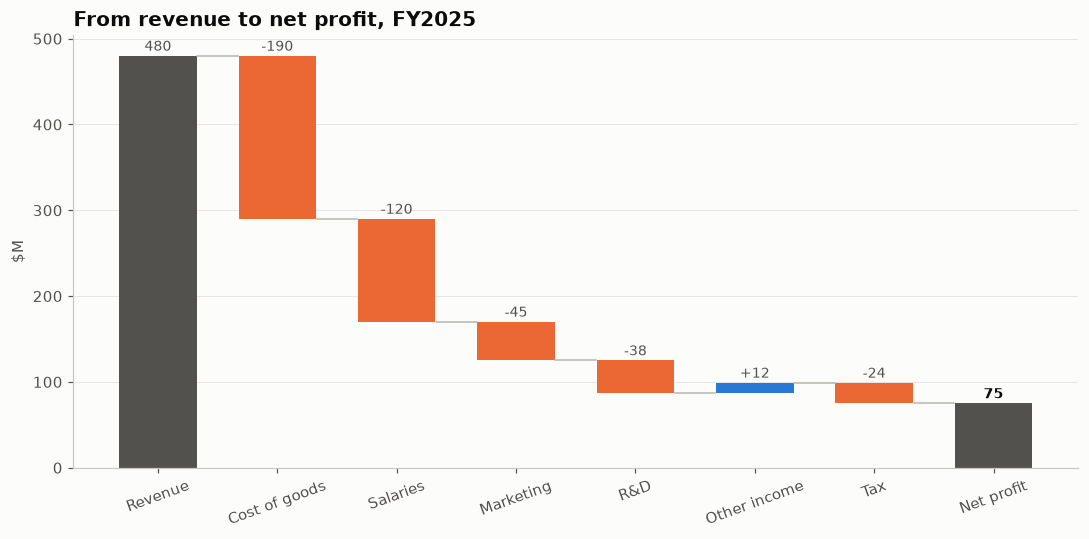

In [3]:
cum = steps.cumsum()
starts = cum - steps
labels = list(steps.index) + ["Net profit"]
fig, ax = plt.subplots(figsize=(10, 5))
for i, (name, v) in enumerate(steps.items()):
    if i == 0:
        color, bottom, h = "#52514e", 0, v
    else:
        color = PALETTE[0] if v >= 0 else PALETTE[1]
        bottom, h = min(starts.iloc[i], cum.iloc[i]), abs(v)
    ax.bar(i, h, bottom=bottom, color=color, width=0.65)
    ax.text(i, bottom + h + 6, f"{v:+,}" if i else f"{v:,}", ha="center", fontsize=9,
            color="#52514e")
    ax.plot([i + 0.33, i + 0.67], [cum.iloc[i]] * 2, color="#b8b7b1", linewidth=1)
net = cum.iloc[-1]
ax.bar(len(steps), net, color="#52514e", width=0.65)
ax.text(len(steps), net + 6, f"{net:,}", ha="center", fontsize=9, fontweight="bold")
ax.set_xticks(range(len(labels)), labels, rotation=20)
ax.set_ylabel("$M")
ax.set_title("From revenue to net profit, FY2025")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Read left to right. Gray bars are totals, blue bars add to the running total and orange bars subtract from it. Revenue of $480M shrinks to a net profit of $75M (about a 16% margin); cost of goods ($190M) is the biggest deduction.

---
Standalone script: [`waterfall_chart.py`](waterfall_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)